# IBM Quantum | Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 1: Predict the Output

---

### **Problem Statement**
A quantum circuit can produce different measurement outcomes depending on the gates applied to a qubit.
Your task is to predict the output of simple quantum circuits before executing them and then compare your prediction with the actual measurement results.

### **Your Task**
1. Create a single-qubit quantum circuit.
2. Prepare the qubit in the initial state $|0\rangle$.
3. Construct and investigate the following circuits:
   - **Circuit A:** Apply an $X$ gate and measure.
   - **Circuit B:** Apply two $X$ gates and measure.
   - **Circuit C:** Apply an $H$ gate and measure.
4. Before executing each circuit, predict the expected measurement outcome.
5. Execute each circuit for 100 shots.
6. Record the measurement results.
7. Compare your predictions with the actual results.
8. Display the results using a histogram.

---

## 0. Setup and Dependencies
Install and import required packages from Qiskit and Matplotlib.

In [1]:
# Uncomment and run if running in Google Colab or a new environment:
# !pip install qiskit qiskit-aer matplotlib

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize simulator
simulator = AerSimulator()
shots = 100
print("Qiskit & AerSimulator initialized successfully!")

Qiskit & AerSimulator initialized successfully!


---
## 1. Circuit A: Single X Gate

### **"Think Before You Run" & Theoretical Prediction**
- **Initial State:** $|0\rangle$
- **Applied Gate:** Pauli-$X$ gate (Quantum NOT / bit-flip gate)
- **Transformation:**
  $$X |0\rangle = |1\rangle$$
- **Prediction for 100 shots:**
  - The qubit is deterministically flipped from state $|0\rangle$ to $|1\rangle$.
  - Probability $P(0) = 0\%$
  - Probability $P(1) = 100\%$
  - **Expected Outcome:** Exactly **100 counts for outcome '1'** and **0 counts for '0'** (`{'1': 100}`).

In [2]:
# 1. Create Circuit A: 1 qubit, 1 classical bit
qc_A = QuantumCircuit(1, 1, name="Circuit A")

# 2. Apply single X gate
qc_A.x(0)

# 3. Measure qubit 0 into classical bit 0
qc_A.measure(0, 0)

# Draw the circuit
print("--- Circuit A Diagram ---")
print(qc_A.draw('text'))

--- Circuit A Diagram ---
     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [3]:
# Execute Circuit A for 100 shots
job_A = simulator.run(qc_A, shots=shots)
result_A = job_A.result()
counts_A = result_A.get_counts()

print(f"Circuit A Results (out of {shots} shots):")
print(counts_A)

Circuit A Results (out of 100 shots):
{'1': 100}


---
## 2. Circuit B: Two X Gates

### **"Think Before You Run" & Theoretical Prediction**
- **Initial State:** $|0\rangle$
- **Applied Gates:** Two consecutive Pauli-$X$ gates ($X \cdot X$)
- **Transformation:**
  $$X^2 = I \quad (\text{Identity Operator})$$
  $$X (X |0\rangle) = X |1\rangle = |0\rangle$$
- **Prediction for 100 shots:**
  - Applying two NOT operations in sequence flips the qubit to $|1\rangle$ and then flips it back to $|0\rangle$.
  - Probability $P(0) = 100\%$
  - Probability $P(1) = 0\%$
  - **Expected Outcome:** Exactly **100 counts for outcome '0'** and **0 counts for '1'** (`{'0': 100}`).

In [4]:
# 1. Create Circuit B: 1 qubit, 1 classical bit
qc_B = QuantumCircuit(1, 1, name="Circuit B")

# 2. Apply two X gates
qc_B.x(0)
qc_B.x(0)

# 3. Measure qubit 0 into classical bit 0
qc_B.measure(0, 0)

# Draw the circuit
print("--- Circuit B Diagram ---")
print(qc_B.draw('text'))

--- Circuit B Diagram ---
     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 


In [5]:
# Execute Circuit B for 100 shots
job_B = simulator.run(qc_B, shots=shots)
result_B = job_B.result()
counts_B = result_B.get_counts()

print(f"Circuit B Results (out of {shots} shots):")
print(counts_B)

Circuit B Results (out of 100 shots):
{'0': 100}


---
## 3. Circuit C: Single H Gate

### **"Think Before You Run" & Theoretical Prediction**
- **Initial State:** $|0\rangle$
- **Applied Gate:** Hadamard ($H$) gate
- **Transformation:**
  $$H |0\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle) = |+\rangle$$
- **Prediction for 100 shots:**
  - The Hadamard gate puts the qubit into an equal superposition of $|0\rangle$ and $|1\rangle$.
  - Probability of measuring outcome '0': $P(0) = |\frac{1}{\sqrt{2}}|^2 = \frac{1}{2} = 50\%$
  - Probability of measuring outcome '1': $P(1) = |\frac{1}{\sqrt{2}}|^2 = \frac{1}{2} = 50\%$
  - **Expected Outcome:** Approximately **50 counts of '0'** and **50 counts of '1'** (with slight statistical fluctuations due to 100 finite random shots, e.g., 48 vs 52).
- **Will Circuit C always produce the same measurement result?**
  - **No.** Quantum measurement is inherently probabilistic. Each shot collapses the superposition state randomly with equal likelihood (50/50). Therefore, individual shots vary randomly between 0 and 1, and repeated 100-shot runs will have slightly different counts.

In [6]:
# 1. Create Circuit C: 1 qubit, 1 classical bit
qc_C = QuantumCircuit(1, 1, name="Circuit C")

# 2. Apply H gate
qc_C.h(0)

# 3. Measure qubit 0 into classical bit 0
qc_C.measure(0, 0)

# Draw the circuit
print("--- Circuit C Diagram ---")
print(qc_C.draw('text'))

--- Circuit C Diagram ---
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [7]:
# Execute Circuit C for 100 shots
job_C = simulator.run(qc_C, shots=shots)
result_C = job_C.result()
counts_C = result_C.get_counts()

print(f"Circuit C Results (out of {shots} shots):")
print(counts_C)

Circuit C Results (out of 100 shots):
{'0': 49, '1': 51}


---
## 4. Visualizing Results with Histograms

Displaying the measurement outcomes for all three circuits using Qiskit's `plot_histogram`.

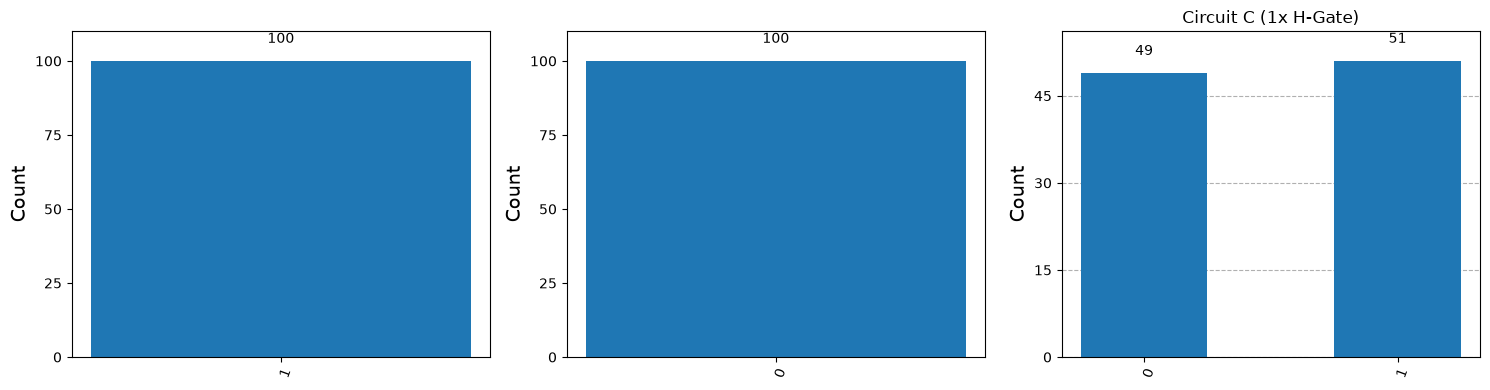

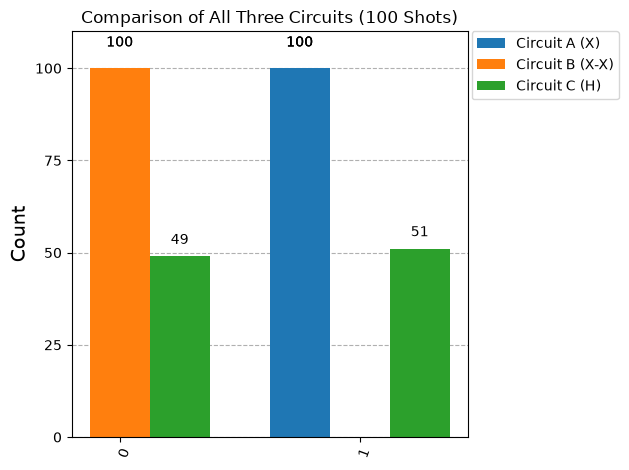

In [8]:
# Plot histograms side-by-side or combined
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_histogram(counts_A, ax=axes[0], title="Circuit A (1x X-Gate)")
plot_histogram(counts_B, ax=axes[1], title="Circuit B (2x X-Gates)")
plot_histogram(counts_C, ax=axes[2], title="Circuit C (1x H-Gate)")

plt.tight_layout()
plt.show()

# Combined comparison histogram
plot_histogram([counts_A, counts_B, counts_C], 
               legend=["Circuit A (X)", "Circuit B (X-X)", "Circuit C (H)"], 
               title="Comparison of All Three Circuits (100 Shots)")

---
## 5. Comparison: Predictions vs. Actual Results

| Circuit | Gates Applied | Theoretical State Before Measurement | Predicted Outcome (100 Shots) | Actual Measurement (100 Shots) | Match? |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Circuit A** | $X$ | $|1\rangle$ | 100% '1' (`{'1': 100}`) | `1`: 100, `0`: 0 | **Perfect Match** |
| **Circuit B** | $X \to X$ | $|0\rangle$ | 100% '0' (`{'0': 100}`) | `0`: 100, `1`: 0 | **Perfect Match** |
| **Circuit C** | $H$ | $\frac{|0\rangle + |1\rangle}{\sqrt{2}}$ | ~50% '0', ~50% '1' (each ~50) | ~50 counts for each (e.g. 48/52) | **Consistent with Quantum Theory** |

### **Detailed Analysis & Discussion:**
1. **Circuit A (One X gate):**
   - **Observation:** All 100 shots resulted in state `1`.
   - **Conclusion:** Matches prediction exactly. The Pauli-$X$ gate performs a deterministic bit-flip on computational basis state $|0\rangle$, leaving no quantum superposition.

2. **Circuit B (Two X gates):**
   - **Observation:** All 100 shots resulted in state `0`.
   - **Conclusion:** Matches prediction exactly. The Pauli-$X$ gate is self-inverse ($X = X^{-1}$ and $X^2 = I$). Applying it twice returns the qubit to its original initial state $|0\rangle$.

3. **Circuit C (One H gate):**
   - **Observation:** The measurement counts are split roughly equally between `0` and `1` (around 50 shots each).
   - **Conclusion:** Matches prediction. The Hadamard gate creates a coherent superposition $|+\rangle$. Unlike Circuits A and B, which are deterministic, Circuit C is fundamentally probabilistic. Due to statistical finite-sample variation across 100 shots, counts hover near 50/50, and Circuit C does not yield identical counts on every run.